# Fig. 5b: a deep mutation rate scan (DmuS) simulated from the Expt 1 barcodes

Splitting one barcode library across many strains trades statistical depth per strain
for the number of strains measured at once.  This panel asks how little depth is
enough, by partitioning the 119,672 Expt 1 barcodes into virtual "strains" of 50, 100,
200 and 400 barcodes and inferring a mutation rate for each independently.

Each strain is fitted by the maximum-likelihood generalisation of the classical P0
method (SI section 5.7).  Only the zero/non-zero indicator per lineage is used:

    L(mu) = prod_i [ exp(-mu N_i) (1 - s_i) + (1 - exp(-mu N_i)) s_i ]

with s_i = 1 if lineage i produced at least one mutant and N_i its pre-selection
population size.  Discarding the mutant counts themselves is what makes the method
cheap enough to run thousands of times, and is why ~100 barcodes suffice.

Reads are converted to mutant numbers with the calibration of SI Eq. 10,
m_i = alpha * (r_i / sum_j r_j) * M_cfu, taking alpha and M_cfu from the Fig. 2
least-squares fit so that this panel and Fig. 2 describe the same experiment on the
same scale.

The resulting median mu is biased slightly low relative to the full-distribution fit,
by about 1.4-fold.  This is inherent to the estimator: a lineage counts as
mutant-bearing only once its calibrated mutant number reaches one, so lineages that
produced a single mutant fall partly below the threshold and go uncounted.  About 11%
of lineages clear the threshold here, against the ~15% implied by the fitted rate.

Runtime: ~20 s.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import time

import numpy as np
import matplotlib.pyplot as plt

from barfly import expt1                           # noqa: E402
from barfly.fitting import p0_mle                  # noqa: E402
from barfly.plotting import use_paper_style        # noqa: E402

OUTPUT_DIR = ROOT / "output"
CACHE_DIR = ROOT / "cache"

BARCODES_PER_STRAIN = [50, 100, 200, 400]
MU_GRID = np.logspace(-8, -2, 1000)

In [2]:
def scan_virtual_strains(counts_pre, counts_post, total_mutants, barcodes_per_strain):
    """Infer mu independently for each consecutive block of barcodes.

    Returns one array of maximum-likelihood rates per requested strain size.
    """
    total_pre = counts_pre.sum()
    total_post = counts_post.sum()
    n_barcodes = len(counts_post)

    rates = {}
    for strain_size in barcodes_per_strain:
        per_strain = []
        for start in range(0, n_barcodes - strain_size, strain_size):
            block = slice(start, start + strain_size)
            mutants = total_mutants * counts_post[block] / total_post
            population = expt1.TOTAL_CELLS * counts_pre[block] / total_pre
            best_mu, _ = p0_mle(mutants >= 1, population, MU_GRID)
            per_strain.append(best_mu)
        rates[strain_size] = np.array(per_strain)
    return rates

In [3]:
def plot_rate_histograms(rates, path):
    """One histogram of inferred mu per strain size, sharing a common mu axis."""
    bin_edges = np.concatenate(([0], np.logspace(-7, -4.9, 50)))
    fig, axes = plt.subplots(len(rates), 1, sharex=True)
    fig.set_size_inches(4, len(rates) * 2)

    for axis, (strain_size, mu_values) in zip(axes, sorted(rates.items())):
        axis.hist(mu_values, bins=bin_edges, color="k", edgecolor="gray")
        axis.set_xscale("log")
        y_max = axis.get_ylim()[1]
        axis.set_yticks(np.arange(0, y_max + 1, 50 if y_max > 150 else 25))
        axis.text(0.01, 0.95,
                  f" n = {len(mu_values)} 'strains'\n {strain_size} bcds each",
                  transform=axis.transAxes, verticalalignment="top", fontsize=12)

    plt.tight_layout()
    plt.savefig(path)
    plt.show()

119672 barcodes; alpha = 4.292, total mutants = 198572
10.93% of lineages reach one mutant
    50 barcodes/strain:  2393 strains, median mu = 1.473e-06, fold spread = 1.78
   100 barcodes/strain:  1196 strains, median mu = 1.493e-06, fold spread = 1.44
   200 barcodes/strain:   598 strains, median mu = 1.473e-06, fold spread = 1.27
   400 barcodes/strain:   299 strains, median mu = 1.473e-06, fold spread = 1.17

median mu = 1.493e-06 = 0.73x the full-distribution fit (2.046e-06)


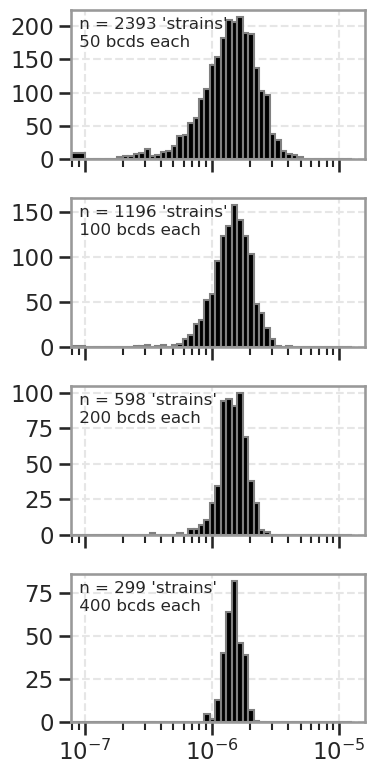

Done in 16.7s.


In [4]:
started = time.time()
use_paper_style()
OUTPUT_DIR.mkdir(exist_ok=True)

fit = np.load(CACHE_DIR / "expt1_fit.npz")
alpha = float(fit["alpha_ls"][-1])
mu_full_distribution = float(fit["mu_ls"][-1])

_, counts_pre, counts_post, reads_post = expt1.load()
# Reads to absolute mutant numbers, SI Eq. 10, with alpha and M_cfu taken from
# the Fig. 2 fit so both figures describe the experiment on the same scale.
total_mutants = alpha * (counts_post.sum() / reads_post) * expt1.PLATED_CFU

print(f"{len(counts_post)} barcodes; alpha = {alpha:.3f}, "
      f"total mutants = {total_mutants:.0f}")
fraction_over_threshold = np.mean(
    total_mutants * counts_post / counts_post.sum() >= 1)
print(f"{100 * fraction_over_threshold:.2f}% of lineages reach one mutant")

rates = scan_virtual_strains(counts_pre, counts_post, total_mutants,
                             BARCODES_PER_STRAIN)
for strain_size, mu_values in sorted(rates.items()):
    fold_spread = np.exp(np.std(np.log(mu_values)))
    print(f"  {strain_size:4d} barcodes/strain: {len(mu_values):5d} strains, "
          f"median mu = {np.median(mu_values):.3e}, "
          f"fold spread = {fold_spread:.2f}")

median_mu = np.median(rates[100])
print(f"\nmedian mu = {median_mu:.3e} = "
      f"{median_mu / mu_full_distribution:.2f}x the full-distribution fit "
      f"({mu_full_distribution:.3e})")

plot_rate_histograms(rates, OUTPUT_DIR / "fig05b_p0MutationRate.svg")
print(f"Done in {time.time() - started:.1f}s.")

In [5]:
sys.path.insert(0, str(ROOT))